In [1729]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path
from scipy.stats import chi2_contingency
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# Configure plotting
%matplotlib inline
plt.style.use('default')
sns.set_palette("husl")

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


---

In [1730]:
project_root = Path().resolve()
train_path = project_root / 'data' / 'train.csv'
test_path = project_root / 'data' / 'test.csv'

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

print(f"Training data loaded: {df_train.shape}")
print(f"Test data loaded: {df_test.shape}")

Training data loaded: (7094, 25)
Test data loaded: (1774, 25)


In [1731]:
project_root = Path.cwd()
print(f"Project root: {project_root}")

# Define color palette for visualizations
palettehex = [
    '#6A9C89', '#C1D8C3', '#CD5C08', '#E19898', 
    '#7FA1C3', '#F7D060', '#6482AD', '#E2BBE9',
    '#C96868', '#FADFA1', '#FFF4EA'
]

print("Project configuration complete")

Project root: /Users/ss/Documents/ECAP2/decision_trees/decision-tree-challenge
Project configuration complete


## 1. Setup & Configuration

# Data Exploration & Feature Engineering

This notebook performs comprehensive exploratory data analysis (EDA) and feature engineering for the subsidy prediction project.

## 2. Exploratory Data Analysis (EDA)

### First glimpse

In [1732]:
df_train.head()

,nom_du_projet,resume_du_projet,montant_engage,numero_ej,numero_operateur,opérateur,demarche,nom_region,nom_departement,code_departement,...,siret,activitePrincipale,codePostal,dateCreation,categorieEntreprise,trancheEffectifsUniteLegale,societeMissionUniteLegale,etatAdministratifEtablissement,anneeEffectifsEtablissement,economieSocialeSolidaireUniteLegale
0,"Changement des fenêtres ,des portes et pose de...","Suite aux différents audits, il convient de fi...",20710.00,2.104489e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Normandie,Eure,27,...,2.000561e+13,84.11Z,27160.0,2016-01-01,PME,12,NaN,A,2023.0,N
1,ZAC Bernard Duval,La ZAC Claude Bernard / Alexandre Duval à Renn...,200000.00,2.104469e+09,NaN,NaN,Recyclage foncier,Bretagne,Ille-et-Vilaine,35,...,5.231896e+13,42.99Z,35200.0,2010-05-10,ETI,03,NaN,A,2023.0,N
2,Travaux d'urgence de confortement et d'aménage...,Suites aux intempéries du début du mois de déc...,14157.02,2.104386e+09,NaN,NaN,Appui aux collectivités de montagne soumises à...,Provence-Alpes-Côte d'Azur,Hautes-Alpes,05,...,2.000673e+13,84.11Z,5230.0,2017-01-01,PME,12,NaN,A,2023.0,N
3,Rénovation thermique de l'école de GERBEPAL - ...,La commune de GERBÉPAL souhaite rénover le bât...,202019.00,2.104371e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Grand Est,Vosges,88,...,2.188020e+13,84.11Z,88430.0,1999-12-25,PME,11,NaN,A,2023.0,N
4,Rénovation énergétique du Centre Omnisport de ...,Situé à proximité du quartier de Marbé au nord...,587251.00,2.104409e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Bourgogne-Franche-Comté,Saône-et-Loire,71,...,2.171027e+13,84.11Z,71000.0,1983-03-01,ETI,42,NaN,A,2023.0,N


In [1733]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 25 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   nom_du_projet                        7094 non-null   object 
 1   resume_du_projet                     6917 non-null   object 
 2   montant_engage                       7094 non-null   float64
 3   numero_ej                            6025 non-null   float64
 4   numero_operateur                     1072 non-null   object 
 5   opérateur                            1072 non-null   object 
 6   demarche                             6962 non-null   object 
 7   nom_region                           6929 non-null   object 
 8   nom_departement                      6929 non-null   object 
 9   code_departement                     6929 non-null   object 
 10  siret_beneficiaire                   6930 non-null   float64
 11  raison_sociale_beneficiaire   

In [1734]:
for col in df_train.select_dtypes('object').columns:
    df_train[col] = df_train[col].astype('category')
    df_test[col] = df_test[col].astype('category')

df_train.info()
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 25 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        7094 non-null   category
 1   resume_du_projet                     6917 non-null   category
 2   montant_engage                       7094 non-null   float64 
 3   numero_ej                            6025 non-null   float64 
 4   numero_operateur                     1072 non-null   category
 5   opérateur                            1072 non-null   category
 6   demarche                             6962 non-null   category
 7   nom_region                           6929 non-null   category
 8   nom_departement                      6929 non-null   category
 9   code_departement                     6929 non-null   category
 10  siret_beneficiaire                   6930 non-null   float64 
 11  raison_sociale_be

In [1735]:
df_train.columns

df_train.columns = df_train.columns.str.replace(' ', '_').str.lower()
df_train.columns = df_train.columns.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')

df_test.columns = df_test.columns.str.replace(' ', '_').str.lower()
df_test.columns = df_test.columns.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')

---

## 3. Data Cleaning & Manipulation

### `trancheeffectifsunitelegale`

This step is needed to treat the `trancheeffectifsunitelegale` values according to its type. This variable represents the ordinal structure, however it contains NN value that correspond to false information.

In [1736]:
df_train["trancheeffectifsunitelegale"].value_counts()
df_train['is_false_info'] = (df_train['trancheeffectifsunitelegale'] == 'NN').astype(int)
df_test['is_false_info'] = (df_test['trancheeffectifsunitelegale'] == 'NN').astype(int)

ordinal_map = {
    'NN': 0,
    '00': 1,
    '01': 2,
    '02': 3,
    '03': 4,
    '11': 5,
    '12': 6,
    '21': 7,
    '22': 8,
    '31': 9,
    '32': 10,
    '41': 11,
    '42': 12,
    '51': 13,
    '52': 14,
    '53': 15
}

for df_data in [df_train, df_test]:
    df_data['trancheeffectifsunitelegale'] = (
        df_data['trancheeffectifsunitelegale']
        .astype('string')
        .str.strip()
        .fillna('NN')
    )
    df_data['tranche_effectif_ord'] = df_data['trancheeffectifsunitelegale'].map(ordinal_map)

In [1737]:
df_test[df_test['tranche_effectif_ord'].isna()][['trancheeffectifsunitelegale']].head()
df_train[df_train['tranche_effectif_ord'].isna()][['trancheeffectifsunitelegale']].head()

,trancheeffectifsunitelegale


### Cardinality check

The following stages will research the cardinality of the categorical variables.

In [1738]:
from utilites import clean_text

categorical_cols = df_train.select_dtypes('category').columns

for df_data in [df_train, df_test]:
    for col in df_data[categorical_cols]:
        df_data[col] = df_data[col].apply(clean_text)

In [1739]:
unique_values = df_train[categorical_cols].nunique().sort_values(ascending=False).to_dict()

low_cardinality = []
high_cardinality = []
mid_cardinality = []

for var, count in unique_values.items():
    if count < 7:
        low_cardinality.append(var)
    elif count >= 7 and count < 30:
        mid_cardinality.append(var) 
    else:
        high_cardinality.append(var)
    print(f"{var}: {count} unique values")


resume_du_projet: 6772 unique values
nom_du_projet: 6660 unique values
raison_sociale_beneficiaire: 5139 unique values
code_commune: 4486 unique values
nom_commune: 4454 unique values
numero_operateur: 1072 unique values
datecreation: 1000 unique values
activiteprincipale: 146 unique values
nom_departement: 106 unique values
code_departement: 106 unique values
forme_juridique_beneficiaire: 61 unique values
nom_region: 23 unique values
demarche: 17 unique values
operateur: 7 unique values
categorieentreprise: 3 unique values
economiesocialesolidaireunitelegale: 2 unique values
societemissionunitelegale: 1 unique values
etatadministratifetablissement: 1 unique values


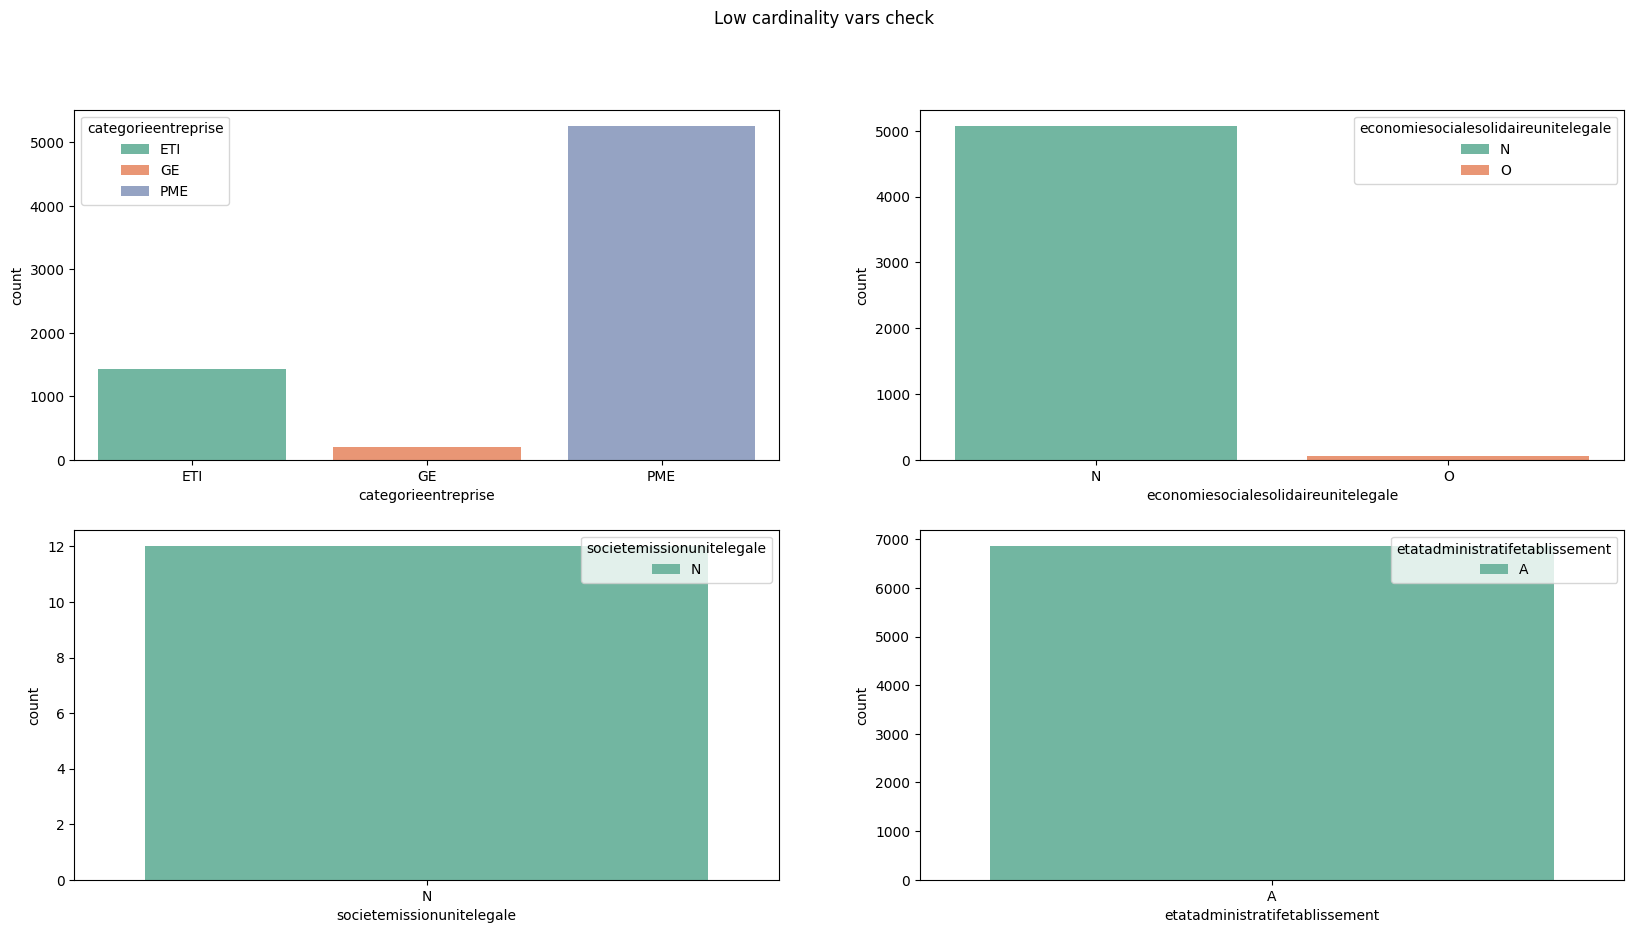

In [1740]:
fig, axes = plt.subplots(2, 2, figsize=(20, 10))
fig.suptitle('Low cardinality vars check')
for i, col in enumerate(low_cardinality[:4]):
    sns.countplot(ax=axes[i // 2, i % 2], x=col, data=df_train, palette="Set2", hue=df_train[col])
plt.show()

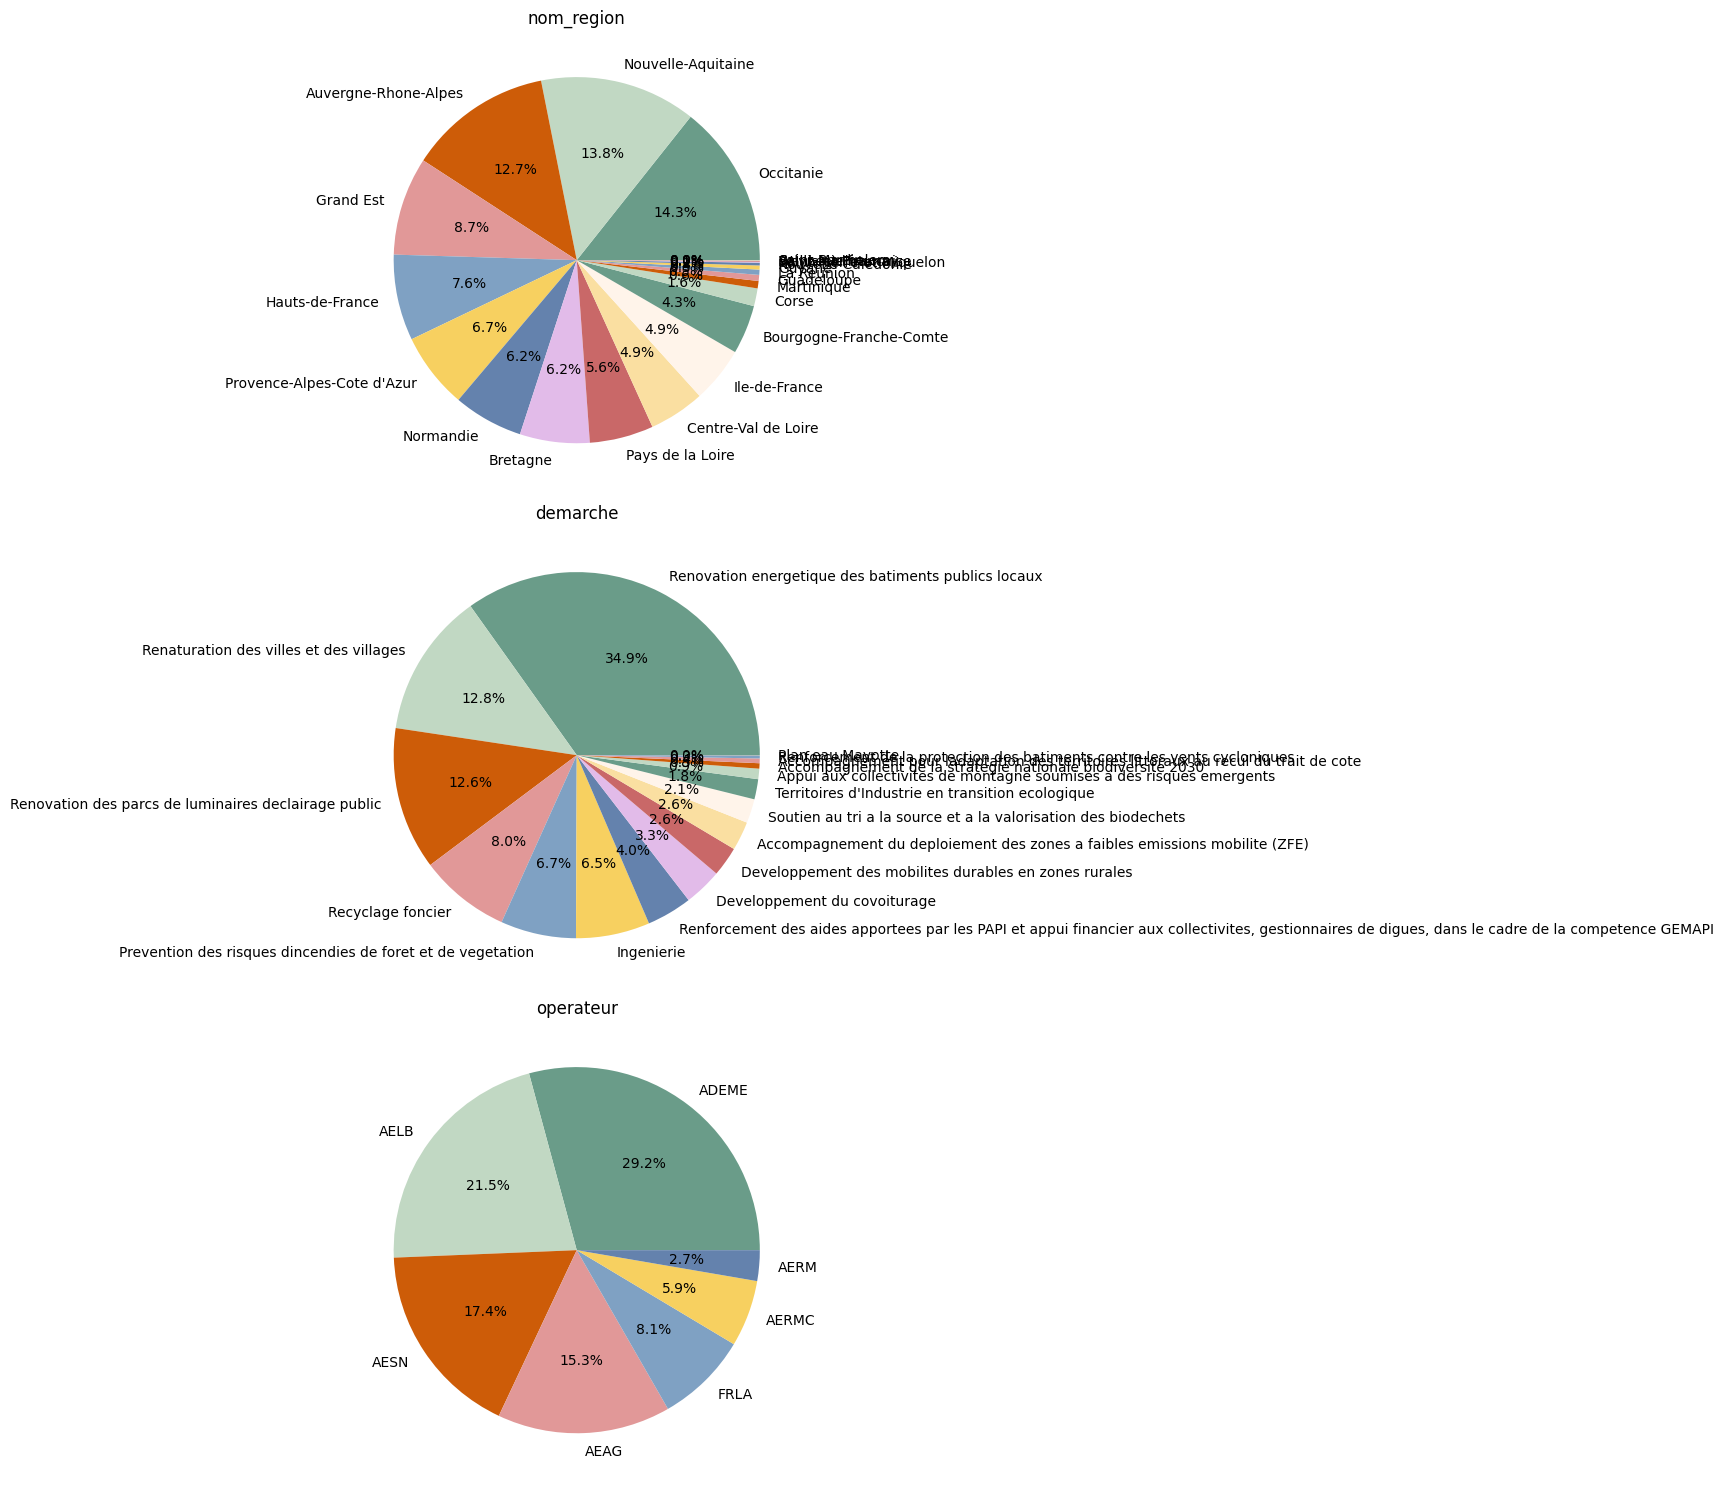

In [1741]:
n_rows = len(mid_cardinality)

fig, axes = plt.subplots(n_rows, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(mid_cardinality):
    df_train[col].value_counts().plot(
        kind='pie',
        ax=axes[i],
        title=col,
        autopct='%1.1f%%',
        colors=palettehex
    )
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

### Numeric variable overview

**`Subsidy size`**

We have detected only 1 numerical variable which is a subsidy size. However, the age of the company is a subject to categorical-to-numerical transition (`dateCreation`).

In [1742]:
stats = df_train["montant_engage"].describe()

for label, value in stats.items():
    print(f"{label}: {value:.0f}")

count: 7094
mean: 181802
std: 377617
min: 288
25%: 18111
50%: 63241
75%: 200688
max: 11600000


In [1743]:
df_train["log_montant_engage"] = np.log(df_train["montant_engage"])
df_test["log_montant_engage"] = np.log(df_test["montant_engage"])

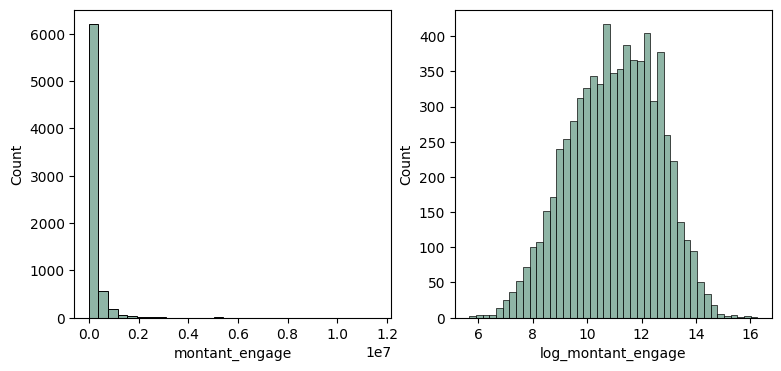

In [1744]:
fig, ax = plt.subplots(1,2,figsize=(9, 4))
sns.histplot(data=df_train, x="montant_engage", 
             color=palettehex[0], 
             ax=ax[0],
             bins=30)
sns.histplot(data=df_train, x="log_montant_engage", 
             color=palettehex[0], 
             ax=ax[1])
plt.show()

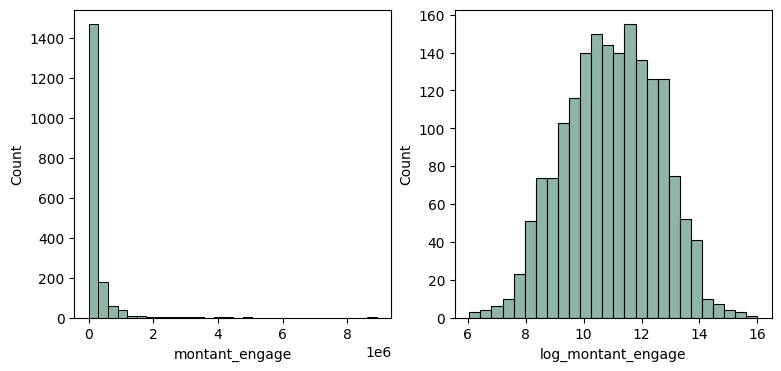

In [1745]:
fig, ax = plt.subplots(1,2,figsize=(9, 4))
sns.histplot(data=df_test, x="montant_engage", 
             color=palettehex[0], 
             ax=ax[0],
             bins=30)
sns.histplot(data=df_test, x="log_montant_engage", 
             color=palettehex[0], 
             ax=ax[1])
plt.show()

The target variable looks way more readable with the log tranformation applied.

**`Companies' age`**

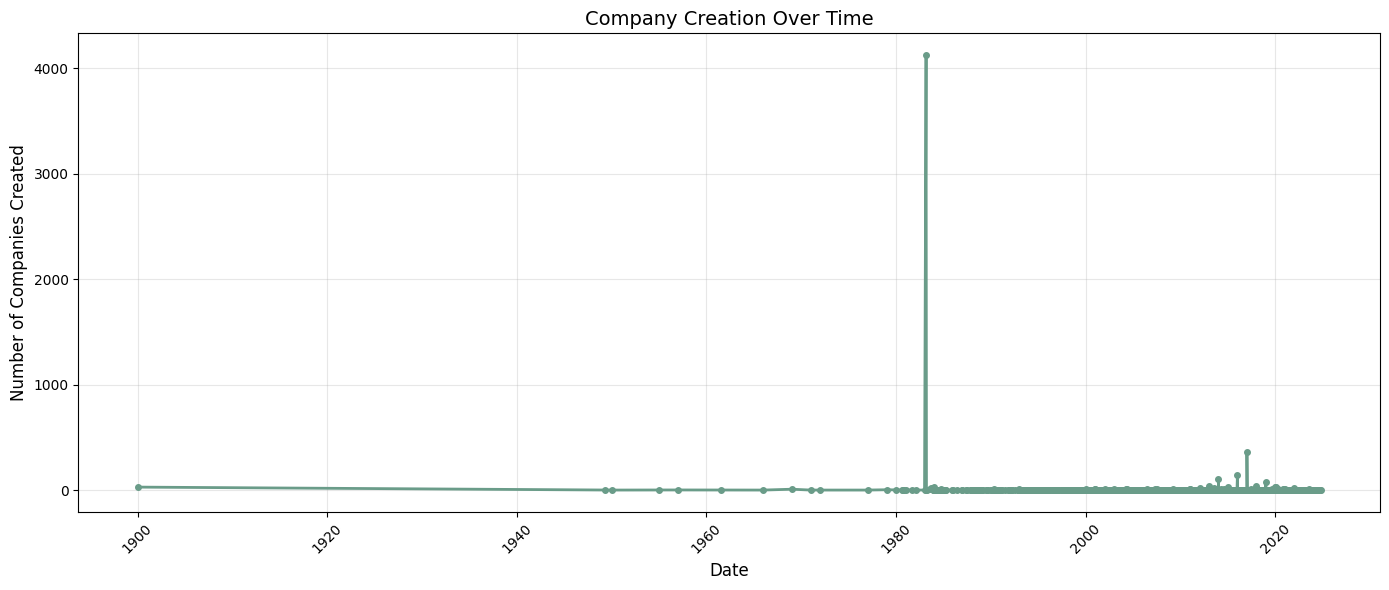

In [1746]:
for df_data in [df_train, df_test]:
    df_data["datecreation"] = pd.to_datetime(df_data["datecreation"], format='%Y-%m-%d')
    df_data["creation_year"] = df_data["datecreation"].dt.year
    # df_data["creation_month"] = df_data["datecreation"].dt.month
    # df_data["creation_quarter"] = df_data["datecreation"].dt.quarter
    # Create consecutive quarter: (year * 4 + quarter) for ordinal progression
    # df_data["quarter_ordinal"] = (df_data["creation_year"] * 4 + df_data["creation_quarter"])

time_counts = df_train.groupby('datecreation').size().reset_index(name='count')
time_counts['datecreation'] = pd.to_datetime(time_counts['datecreation'])

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(time_counts['datecreation'], time_counts['count'], 
        color=palettehex[0], linewidth=2, marker='o', markersize=4)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Number of Companies Created', fontsize=12)
ax.set_title('Company Creation Over Time', fontsize=14)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

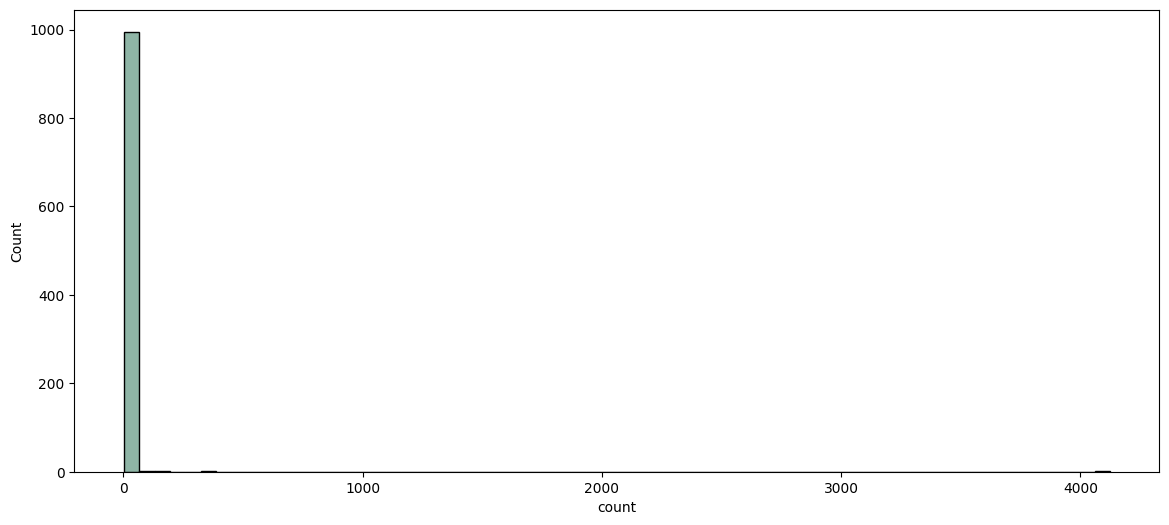

Maximum value 4124 found at index 20 corresponding to date 1983-03-01 00:00:00


In [1747]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.histplot(data=time_counts, x="count", 
             color=palettehex[0], 
             ax=ax)
plt.show()

for i, val in enumerate(time_counts['count']):
    max_values = time_counts['count'].max()
    if val == max_values:
        print(f"Maximum value {val} found at index {i} corresponding to date {time_counts['datecreation'][i]}")

The anomalous date was detected. 4124 firms were created in this specific date with is considered to be abnormally extreme. We'll try to find some logical explanation of this outlier, otherwise, we'll need to get rid of it since it touches a significant amount of observation, or create a special category for this variable.

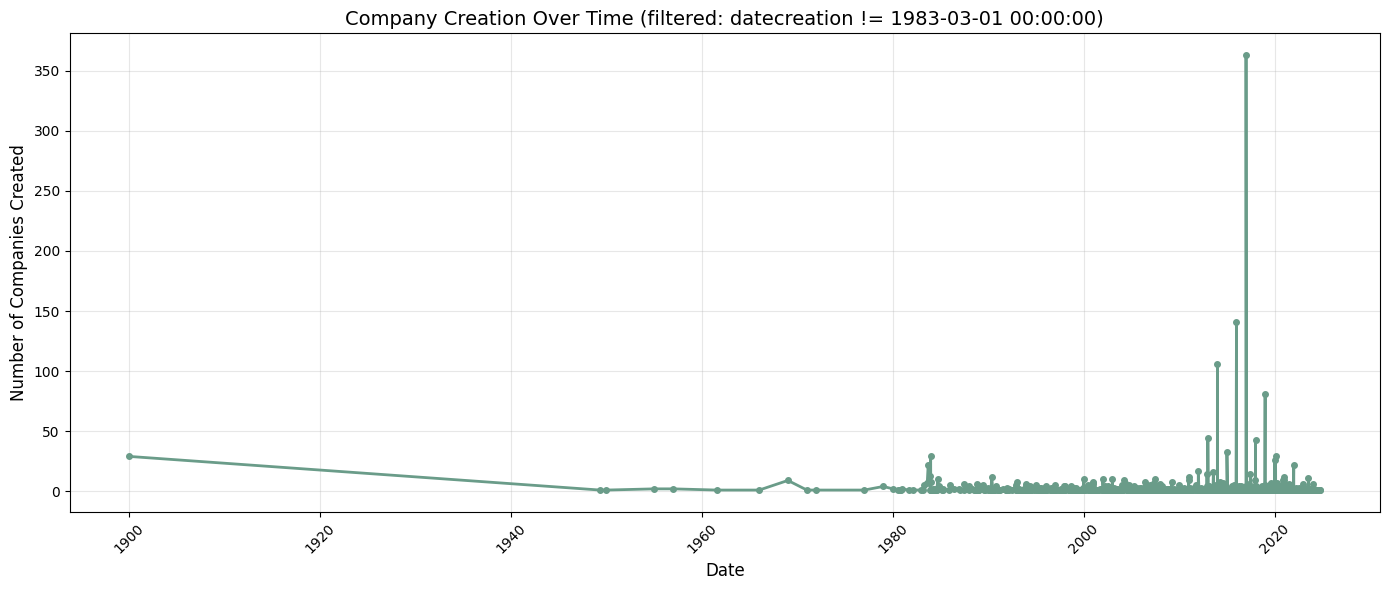

In [1748]:
# Filter out extreme outliers
threshold = "1983-03-01 00:00:00"
time_counts_filtered = time_counts[time_counts['datecreation'] != threshold]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(time_counts_filtered['datecreation'], time_counts_filtered['count'], 
        color=palettehex[0], linewidth=2, marker='o', markersize=4)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Number of Companies Created', fontsize=12)
ax.set_title(f'Company Creation Over Time (filtered: datecreation != {threshold})', fontsize=14)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [1749]:
today = pd.Timestamp.today()
for df_data in [df_train, df_test]:
    df_data["age_entreprise"] = (today - df_data["datecreation"]).dt.days / 365.25
    df_data["age_entreprise_m"] = (today - df_data["datecreation"]).dt.days / 30.44

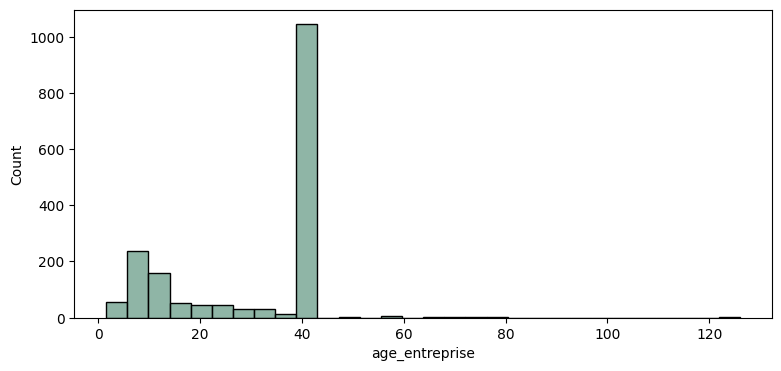

count    1731.000000
mean       31.916520
std        15.756592
min         1.568789
25%        13.065024
50%        42.904860
75%        42.904860
max       126.064339
Name: age_entreprise, dtype: float64

In [1750]:
#age variable distribution
fig, ax = plt.subplots(1,1,figsize=(9, 4))
sns.histplot(data=df_data, x="age_entreprise", 
             color=palettehex[0], 
             ax=ax,
             bins=30)
plt.show()

df_data["age_entreprise"].describe()

We will treat these extreme values as "input errors". Thus, we'll make a medium imputation and create a dummy for errors aside.

In [1751]:
# Identify enterprises created at the anomalous threshold date
threshold = "1983-03-01 00:00:00"

# Compute median age on TRAIN data only
is_extreme_age_train = df_train['datecreation'] == threshold
df_train['is_age_error'] = is_extreme_age_train.astype(int)
df_train.loc[is_extreme_age_train, 'age_entreprise'] = np.nan
mean_age = df_train['age_entreprise'].mean()
df_train['age_entreprise'] = df_train['age_entreprise'].fillna(mean_age)

# Apply same threshold and mean to TEST
is_extreme_age_test = df_test['datecreation'] == threshold
df_test['is_age_error'] = is_extreme_age_test.astype(int)
df_test.loc[is_extreme_age_test, 'age_entreprise'] = np.nan
df_test['age_entreprise'] = df_test['age_entreprise'].fillna(mean_age)  #Use train mean     
print(f"Number of age errors identified (created on {threshold}): {is_extreme_age_train.sum()}")
print(f"Mean age used for imputation: {mean_age:.2f} years")

Number of age errors identified (created on 1983-03-01 00:00:00): 4124
Mean age used for imputation: 16.88 years


### NA check

In [1752]:
na = df_train.isna().sum()/df_train.shape[0]*100

px.bar(na.sort_values(),
         title = "Pourcentage de valeurs manquantes par variable",
         color_discrete_sequence = palettehex[0:1],
         template='ggplot2',
         range_y = [0,100],
         width=800,
         labels={'value':'%', 'index':''},
         color=None
        ).update_traces(showlegend=False).update_xaxes(tickangle=45)

In [1753]:
na.sort_values()

nom_du_projet                           0.000000
age_entreprise                          0.000000
log_montant_engage                      0.000000
tranche_effectif_ord                    0.000000
is_false_info                           0.000000
trancheeffectifsunitelegale             0.000000
is_age_error                            0.000000
montant_engage                          0.000000
code_commune                            1.860727
nom_commune                             1.860727
demarche                                1.860727
raison_sociale_beneficiaire             1.945306
forme_juridique_beneficiaire            1.945306
siret_beneficiaire                      2.311813
nom_region                              2.325909
creation_year                           2.325909
datecreation                            2.325909
siret                                   2.325909
activiteprincipale                      2.325909
age_entreprise_m                        2.325909
code_departement    

Before choosing candidates for the deletion, we'll take a look at the variables' meaning and try to understand if the fact that the variable is missing is something explained by its nature.

- `societemissionunitelegale`: Introduced only in 2019.
- `economiesocialesolidaireunitelegale`: Missing ≠ “unknown”; missing = “not part of the ESS perimeter and not declared”.
- `numero_operateur`: These are identifiers used only for specific legal setups
- `numero_ej`: Missing when there is no EJ separate from the legal unit, which happens in many cases.
- `age_entreprise`: imputed and a dummy added

So, these NAs are structural and we suppose that the model will loose some of necessary information with exclusion of these variables. We have decided to keep them selectively, and make imputation based on the meaning of each variable.

### Imputation and Clean-up

In [1754]:
for df_data in [df_train, df_test]: 
    print(df_data['societemissionunitelegale'].value_counts(dropna=False))
    print(df_data['anneeeffectifsetablissement'].value_counts(dropna=False))
    print(df_data['numero_ej'].value_counts(dropna=False))
    print(df_data['economiesocialesolidaireunitelegale'].value_counts(dropna=False))
    print(df_data['operateur'].value_counts(dropna=False))
    print(df_data['siret'].value_counts(dropna=False))
    print(df_data['siret_beneficiaire'].value_counts(dropna=False))

societemissionunitelegale
NaN    7082
N        12
Name: count, dtype: int64
anneeeffectifsetablissement
2023.0    6700
NaN        394
Name: count, dtype: int64
numero_ej
NaN             1069
2.104591e+09       4
2.104503e+09       2
2.104575e+09       2
2.104323e+09       2
                ... 
2.104565e+09       1
2.104598e+09       1
2.104371e+09       1
2.104320e+09       1
2.104414e+09       1
Name: count, Length: 6019, dtype: int64
economiesocialesolidaireunitelegale
N      5069
NaN    1966
O        59
Name: count, dtype: int64
operateur
NaN      6022
ADEME     313
AELB      230
AESN      186
AEAG      164
FRLA       87
AERMC      63
AERM       29
Name: count, dtype: int64
siret
NaN             165
2.000931e+13     29
2.582006e+13     16
2.000693e+13     15
2.175000e+13     15
               ... 
2.000675e+13      1
2.503001e+13      1
2.000406e+13      1
8.337188e+13      1
2.834005e+13      1
Name: count, Length: 5238, dtype: int64
siret_beneficiaire
NaN             164
2.000931

In [1755]:
for df_data in [df_train, df_test]:
    df_data['numero_ej'] = df_data['numero_ej'].astype('object').fillna('No EJ').astype('category')
    df_data['economiesocialesolidaireunitelegale'] = df_data['economiesocialesolidaireunitelegale'].astype('object').fillna('Not in ESS scope').astype('category')
    df_data['operateur'] = df_data['operateur'].astype('object').fillna('Not applicable').astype('category')

### New features – proxy to regional imbalance

After several training and testing rounds, we want to add another variable to proxy the richeness of each department. we'll add dummy for the capital of the region and the number of citizens. 

In [1756]:
#Import department population mapping from CSV file
population_path = Path(project_root / "data" / "population.csv")
pop_df = pd.read_csv(population_path)

#Clean population data: remove commas and convert to numeric
pop_df['population'] = pop_df['population'].astype(str).str.replace(',', '').astype(float)
dept_population = dict(zip(pop_df['code'].astype(str), pop_df['population']))
print(f"Departments in population file: {len(dept_population)}")

#Compute median population on TRAIN data only
median_pop = pop_df['population'].mean()

# Apply to both train and test
for df_data in [df_train, df_test]:
    df_data['dept_population_proxy'] = df_data['code_departement'].astype(str).map(dept_population)
    df_data['dept_population_proxy'] = df_data['dept_population_proxy'].fillna(median_pop)

print(f"Population proxy created (range: {df_train['dept_population_proxy'].min():.0f} - {df_train['dept_population_proxy'].max():.0f})")
print(f"Median population used for unmapped depts: {median_pop:.0f}")

Departments in population file: 96
Population proxy created (range: 76648 - 2606646)
Median population used for unmapped depts: 685780


In [1757]:
# Create France region mapping: Metropolitan, Overseas, Other
metro_depts = set(str(i).zfill(2) for i in range(1, 96) if i not in [20])  # 01-19, 21-75, 77-95
corsica_depts = {'2A', '2B'}  # Corsica (20 split into 2A, 2B)
overseas_depts = {'971', '972', '973', '974', '976'}  # Guadeloupe, Martinique, French Guiana, Reunion, Mayotte

metro_depts.update(corsica_depts)  # Include Corsica in Metropolitan

france_region_map = {}
for dept in metro_depts:
    france_region_map[dept] = 'Metropolitan'
for dept in overseas_depts:
    france_region_map[dept] = 'Overseas'

# Default for any unmapped departments
def categorize_france_region(dept_code):
    return france_region_map.get(str(dept_code), 'Other')

# Apply mapping to create France region category
for df_data in [df_train, df_test]:
    df_data['france_region'] = df_data['code_departement'].astype(str).apply(categorize_france_region)
    df_data['is_metropolitan'] = (df_data['france_region'] == 'Metropolitan').astype(int)
    df_data['is_overseas'] = (df_data['france_region'] == 'Overseas').astype(int)

print(df_train['france_region'].value_counts())

france_region
Metropolitan    6758
Other            197
Overseas         139
Name: count, dtype: int64


In [1758]:
#df_data['code_departement'].astype(str).value_counts()
df_data['code_commune'].astype(str).value_counts()

code_commune
nan      34
75056    21
82121    10
13055     8
38185     8
         ..
88160     1
27562     1
73114     1
24010     1
44115     1
Name: count, Length: 1437, dtype: int64

In [1759]:
df_data.groupby("code_commune")["montant_engage"].agg(["count", "mean", "median"]).sort_values(by="count", ascending=False).head(10)


,count,mean,median
code_commune,,,
75056,21,1.552275e+06,700000.000
82121,10,7.662706e+04,14269.000
13055,8,6.033202e+05,502361.660
38185,8,2.887668e+05,75372.000
76540,7,8.080442e+05,156462.000
60639,6,1.452384e+04,12068.435
31555,6,3.892589e+05,262044.000
97416,6,4.771328e+05,266287.500
89024,6,1.595577e+05,71583.000


In [1760]:
# Target encode code_departement (mean subsidy by department) - NO SMOOTHING
dept_target_encoding = df_train.groupby('code_departement')['montant_engage'].agg(['mean']).reset_index()
dept_target_encoding.columns = ['code_departement', 'dept_mean_subsidy']

# Merge back to train and test
for df_data in [df_train, df_test]:
    df_data = df_data.merge(dept_target_encoding[['code_departement', 'dept_mean_subsidy']], 
                             on='code_departement', how='left')
    # Fill unmapped with global mean
    global_mean = df_train['montant_engage'].mean()
    df_data['dept_mean_subsidy'] = df_data['dept_mean_subsidy'].fillna(global_mean)

print("Department target encoding created (no smoothing)")
print(dept_target_encoding.sort_values('dept_mean_subsidy', ascending=False).head(10))

# Target encode code_commune (mean subsidy by commune) - NO SMOOTHING
commune_target_encoding = df_train.groupby('code_commune')['montant_engage'].agg(['mean']).reset_index()
commune_target_encoding.columns = ['code_commune', 'commune_mean_subsidy']

# Merge back
for df_data in [df_train, df_test]:
    df_data = df_data.merge(commune_target_encoding[['code_commune', 'commune_mean_subsidy']], 
                             on='code_commune', how='left')
    df_data['commune_mean_subsidy'] = df_data['commune_mean_subsidy'].fillna(global_mean)

print("Commune target encoding created (no smoothing)")

# Frequency ranks (popularity/activity level)
dept_freq = df_train['code_departement'].value_counts().to_dict()
commune_freq = df_train['code_commune'].value_counts().to_dict()

for df_data in [df_train, df_test]:
    df_data['dept_frequency_rank'] = df_data['code_departement'].map(dept_freq).fillna(0)
    df_data['commune_frequency_rank'] = df_data['code_commune'].map(commune_freq).fillna(0)

print("Frequency ranks created")

Department target encoding created (no smoothing)
    code_departement  dept_mean_subsidy
75                75      948564.907429
102              978      841622.980000
104              987      815235.795000
93                93      641460.625000
100              975      602271.146667
92                92      592723.468750
99               974      560032.089375
5                 06      481177.646279
101              977      480000.000000
98               973      427167.814800
Commune target encoding created (no smoothing)
Frequency ranks created


### Drop useless variables after manipulation

In [1761]:
variable2drop=["anneeeffectifsetablissement",
               "societemissionunitelegale",
               "numero_operateur",
               "age_entreprise_m",
               "datecreation",
               "codepostal",
               "code_departement",
               "nom_departement",
               "nom_region",
               "nom_commune",
               "log_montant_engage",
               "trancheeffectifsunitelegale",
               "code_commune", 
               "numero_ej",
               "siret",
               "siret_beneficiaire",
               "raison_sociale_beneficiaire",
               "etatadministratifetablissement"
               ]

for df_data in [df_train, df_test]:
    df_data.drop(variable2drop,
            axis=1, 
            inplace=True)

### Tranform numeric skewed variables to log

In [1762]:
# Automatically detect skewed numeric features and apply log1p
import numpy as np

# Candidate numeric columns (exclude the raw/derived target that already has a log variant)
num_cols = df_train.select_dtypes(include=["number"]).columns.tolist()
exclude_cols = {"montant_engage", "log_montant_engage"}
num_candidates = [c for c in num_cols if c not in exclude_cols]

# Consider only sufficiently continuous columns (exclude binary-like)
continuous_candidates = [c for c in num_candidates if df_train[c].nunique(dropna=True) > 10]

# Compute skewness on TRAIN data only
skew_vals = df_train[continuous_candidates].skew(numeric_only=True)
skew_threshold = 2
skewed_cols = skew_vals[skew_vals.abs() > skew_threshold].index.tolist()

# Only transform columns that are non-negative (safe for log1p)
loggable = [c for c in skewed_cols if (df_train[c].dropna() >= 0).all()]

# Apply log transformations to both train and test
for c in loggable:
    new_col = f"log_{c}"
    df_train[new_col] = np.log1p(df_train[c])
    df_test[new_col] = np.log1p(df_test[c])

print("Skewness (continuous candidates):")
print(skew_vals.sort_values(ascending=False))
print("\nLog-transformed columns:", loggable if loggable else "None")

Skewness (continuous candidates):
age_entreprise            5.942769
commune_frequency_rank    3.175786
dept_population_proxy     1.237218
dept_frequency_rank       0.468155
tranche_effectif_ord      0.221964
creation_year            -0.115575
dtype: float64

Log-transformed columns: ['age_entreprise', 'commune_frequency_rank']


In [1763]:
# Drop original variables that have log-transformed counterparts
# logged_bases = loggable  # from the previous skewness step
# for df_data in [df_train, df_test]:
#     for base_col in logged_bases:
#         df_data.drop(columns=[base_col], inplace=True, errors='ignore')

# print("Dropped originals for log-transformed columns:", logged_bases)

### Shape and na check

In [1764]:
print(f"Train shape: {df_train.shape}, Test shape: {df_test.shape}")
df_test.info()
df_train.info()


Train shape: (7094, 22), Test shape: (1774, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1774 entries, 0 to 1773
Data columns (total 22 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        1774 non-null   object  
 1   resume_du_projet                     1727 non-null   object  
 2   montant_engage                       1774 non-null   float64 
 3   operateur                            1774 non-null   category
 4   demarche                             1740 non-null   category
 5   forme_juridique_beneficiaire         1734 non-null   category
 6   activiteprincipale                   1731 non-null   category
 7   categorieentreprise                  1721 non-null   category
 8   economiesocialesolidaireunitelegale  1774 non-null   category
 9   is_false_info                        1774 non-null   int64   
 10  tranche_effectif_ord                

In [1765]:
na = df_train.isna().sum()/df_train.shape[0]*100
na.sort_values()

nom_du_projet                          0.000000
commune_frequency_rank                 0.000000
dept_frequency_rank                    0.000000
is_overseas                            0.000000
is_metropolitan                        0.000000
france_region                          0.000000
dept_population_proxy                  0.000000
is_age_error                           0.000000
age_entreprise                         0.000000
log_age_entreprise                     0.000000
tranche_effectif_ord                   0.000000
economiesocialesolidaireunitelegale    0.000000
operateur                              0.000000
montant_engage                         0.000000
is_false_info                          0.000000
log_commune_frequency_rank             0.000000
demarche                               1.860727
forme_juridique_beneficiaire           1.945306
creation_year                          2.325909
activiteprincipale                     2.325909
resume_du_projet                       2

### Problems with the data

- 1983 spike - solved
- Useless variables due to its NAs - solved
- Specific encoding - to do
- Textual data - to do 

---

## 4. Encoding & Feature Engineering

### Current Variable Set

We have the following variables after preprocessing and feature engineering:

**Ordinal encoding:**
- `tranche_effectif_ord` (int64)
- `categorieentreprise` (category) - PME < ETI < GE

**Categorical variables (nominal):**
- `operateur` (category)
- `demarche` (category)
- `code_departement` (category)
- `forme_juridique_beneficiaire` (category)
- `activiteprincipale` (category)
- `economiesocialesolidaireunitelegale` (category)

**Binary flags:**
- `is_false_info` (int64)
- ~`is_age_error` (int64)~
- `is_metropolitan` (int64)
- `is_overseas` (int64)

**Numerical (log-transformed):**
- `log_age_entreprise` (float64)
- `log_dept_population_proxy` (float64)

**Text data (to vectorize):**
- `nom_du_projet` (object)
- `resume_du_projet` (object)

**Target variable:**
- `montant_engage` (float64)

In [1766]:
ordinal_columns = [
    'tranche_effectif_ord',
    'categorieentreprise',
    'creation_year',
    # 'creation_month',
    # 'quarter_ordinal',
    'actor_rank'  # Added from forme_juridique aggregation
]

# Nominal (categorical, unordered) - THESE WILL BE OHE ENCODED
nominal_columns = [
    'demarche',              # Aggregated version
    'forme_juridique_grp',   # Aggregated from forme_juridique_beneficiaire
    'naf_grp',               # Aggregated from activiteprincipale
    'operateur_type',        # Aggregated from operateur
    'france_region'          # Created from code_departement
]

text_columns = [
    'nom_du_projet',
    'resume_du_projet'
]

target_var = [
    'montant_engage'
]

# Continuous / numeric features (including log-transformed)
numerical_columns = [
    'age_entreprise',                    # Original age
    'log_age_entreprise',                # Log-transformed age
    'dept_population_proxy',             # Department population
    'log_dept_population_proxy',         # Log-transformed population
    'dept_mean_subsidy_smooth',          # TARGET ENCODED - dept average
    'commune_mean_subsidy_smooth',       # TARGET ENCODED - commune average
    'dept_frequency_rank',               # Department activity level
    'commune_frequency_rank',            # Commune activity level
    'tranche_effectif_ord_te',           # Target encoded effectifs
    'categorieentreprise_te'             # Target encoded company category
]

# Binary flags
binary_columns = [
    'is_age_error',
    'is_false_info',
    'is_metropolitan',
    'is_overseas',
    'has_operator',              # From operateur aggregation
    'is_water_agency',           # From operateur aggregation
    'is_ademe',                  # From operateur aggregation
    'is_financial_operator'      # From operateur aggregation
]

### Aggregation of high cardinality variables

The nominal variables should be treated separately since their values should be either aggregated or encoded as separate variables. Before it's necessary to check the info value of each nominal non-binary variable against the target. 

- `activiteprincipale` - to choose crucial activities and to aggregate the rest of them
- `economiesocialesolidaireunitelegale` - aggregate to binary
- `forme_juridique_beneficiaire` - aggregate to ordinal (?)
- `demarche` - aggregate thematically (many binaries)
- `operateur` - aggregate to binary


I will create functions to aggregate and then encode the high cardinality variables in the following section. 

In [1767]:
def bucket_forme_juridique(x):
    """
    Regroup legal forms into institutional actors for subsidy modeling.
    """
    if pd.isna(x):
        return "Autres"
        
    x = str(x).lower()

    # Local authorities
    if "commune" in x:
        return "Commune"
    
    if any(k in x for k in ["communauté", "communaute", "metropole", "métropole", "epci", "agglo"]):
        return "EPCI_Metropole"
    
    if any(k in x for k in ["département", "departement", "région", "region"]):
        return "Departement_Region"
    
    if "syndicat" in x:
        return "Syndicat"
    
    # State / public operators
    if any(k in x for k in ["agence", "ademe", "établissement public", "etablissement public", "opérateur", "operateur"]):
        return "State_Operator"
    
    # Private companies
    if any(k in x for k in ["sas", "sarl", "sa", "société", "societe", "holding"]):
        return "Entreprise"
    
    # Non-profits
    if any(k in x for k in ["association", "fondation", "ngo"]):
        return "Association_NGO"
    
    # Other public bodies
    if any(k in x for k in ["université", "universite", "chu", "hôpital", "hopital", "lycée", "college"]):
        return "Other_Public"
    
    return "Autres"


In [1768]:
def bucket_naf(code):
    if pd.isna(code):
        return "Public_admin"  # most missing are public

    c = str(code).strip().upper()
    import re
    m = re.match(r"^\D*(\d{2})", c)
    if not m:
        return "Public_admin"
    pref2 = m.group(1)

    if pref2 == "84":
        return "Public_admin"

    if pref2 in {"41", "42", "43", "68"}:
        return "Construction_RealEstate"

    if pref2 in {"35", "36", "37", "38", "39"}:
        return "Utilities"

    if pref2 in {"71", "72", "74", "75"}:
        return "Engineering_Technical"

    if pref2 in {"10", "11", "12", "13", "14", "15", "16", "17", "18",
                 "19", "20", "21", "22", "23", "24", "25", "26", "27",
                 "28", "29", "30", "31", "32", "33"}:
        return "Manufacturing"

    if pref2 in {"85", "86", "87", "88", "90", "91", "92", "93"}:
        return "Social_Edu_Culture"

    # Everything else
    return "Services"


In [1769]:
def bucket_demarche(x):
    """
    Aggregate project types. Keep main categories (3305, 1481, 594, 576, 454, 280).
    Combine small ones (< 150) into 'Autres'.
    """
    if pd.isna(x):
        return "Autres"
    if "Renovation energetique" in x or "luminaires" in x:
        return "Energie"
    if "Renaturation" in x or "Recyclage foncier" in x or "biodiversite" in x:
        return "Biodiversite_sols"
    if "mobilites" in x or "covoiturage" in x or "ZFE" in x:
        return "Mobilites"
    if "incendies" in x or "montagne" in x or "littoraux" in x or "cycloniques" in x:
        return "Risques_climatiques"
    if "PAPI" in x or "GEMAPI" in x or "Plan eau" in x:
        return "Eau"
    if "Ingenierie" in x:
        return "Ingenierie"

    # Combine small categories: biodechets, Territoires d'Industrie, etc.
    return "Autres"

In [1770]:
def bucket_operateur(x):
    if pd.isna(x) or x == "Not applicable":
        return "None"
    if x == "ADEME":
        return "Environmental_agency"
    if x in {"AELB", "AESN", "AEAG", "AERMC", "AERM"}:
        return "Water_agency"
    if x == "FRLA":
        return "Financial_fund"
    return "Other"


In [1771]:
df_agg = df_train.copy()

In [1772]:
#apply all aggregating functions
df_agg["forme_juridique_grp"] = df_agg["forme_juridique_beneficiaire"].map(bucket_forme_juridique)
df_agg["forme_juridique_grp"].value_counts()

df_agg["naf_grp"] = df_agg["activiteprincipale"].map(bucket_naf)
df_agg["naf_grp"].value_counts()

df_agg["ess_bin"] = (df_agg["economiesocialesolidaireunitelegale"] == "O").astype(int)
df_agg["ess_bin"].value_counts()

df_agg["demarche"] = df_agg["demarche"].map(bucket_demarche)
df_agg["demarche"].value_counts()

df_agg["operateur_type"] = df_agg["operateur"].map(bucket_operateur)

#to binanry
df_agg["has_operator"] = (df_agg["operateur_type"] != "None").astype(int)
df_agg["is_water_agency"] = (df_agg["operateur_type"] == "Water_agency").astype(int)
df_agg["is_ademe"] = (df_agg["operateur_type"] == "Environmental_agency").astype(int)
df_agg["is_financial_operator"] = (df_agg["operateur_type"] == "Financial_fund").astype(int)

In [1773]:
df_agg.groupby("operateur_type")["montant_engage"].agg(["count", "mean", "median"])


,count,mean,median
operateur_type,,,
Environmental_agency,313,355198.902684,207389.000
Financial_fund,87,162743.583333,98094.000
None,6022,180765.341363,60599.525
Water_agency,672,112799.220134,50577.000


In [1774]:
df_agg.groupby("naf_grp")["montant_engage"].agg(["count", "mean", "median"])


,count,mean,median
naf_grp,,,
Construction_RealEstate,269,426282.033197,279148.0
Engineering_Technical,56,482220.095179,303901.5
Manufacturing,89,381256.048764,300000.0
Public_admin,6480,160013.006718,56000.0
Services,53,359453.508868,145000.0
Social_Edu_Culture,38,444416.019737,187500.0
Utilities,109,378686.248257,57960.0


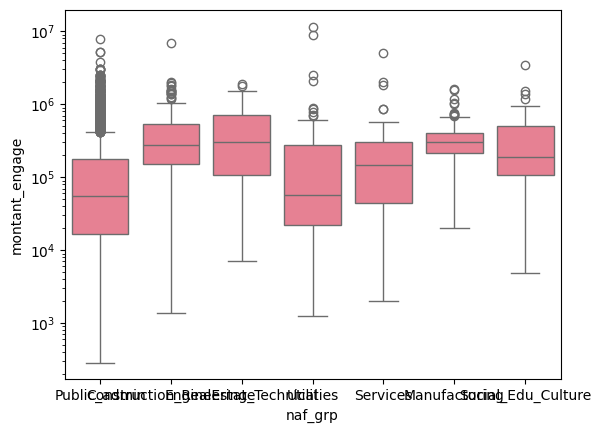

In [1775]:
sns.boxplot(
    x="naf_grp",
    y="montant_engage",
    data=df_agg,
    #order=actor_order.keys()
)
plt.yscale("log")

In [1776]:
# median_map_naf = df_agg.groupby("naf_grp")["montant_engage"].mean()
# df_agg["naf_prior"] = df_agg["naf_grp"].map(median_map_naf)
# df_agg["log_naf_prior"] = np.log1p(df_agg["naf_prior"])


In [1777]:
df_agg.groupby("forme_juridique_grp")["montant_engage"].agg(["count", "mean", "median"]).sort_values(by="mean", ascending=False)    


,count,mean,median
forme_juridique_grp,,,
State_Operator,138,515511.753406,207949.10
Departement_Region,215,466775.860419,157000.00
Entreprise,370,424374.743324,300000.00
EPCI_Metropole,479,267207.492589,108984.21
Autres,242,261298.873058,89554.00
Association_NGO,55,149905.960545,35389.62
Syndicat,560,147768.224661,27840.50
Commune,5035,134849.666941,52803.71


In [1778]:
actor_order = {
    "Syndicat": 2,
    "Commune": 1,
    "Association_NGO": 2,
    "Autres": 3,
    "EPCI_Metropole": 3,
    "Departement_Region": 4,
    "State_Operator": 5,
    "Entreprise": 4
}
df_agg["actor_rank"] = df_agg["forme_juridique_grp"].map(actor_order)


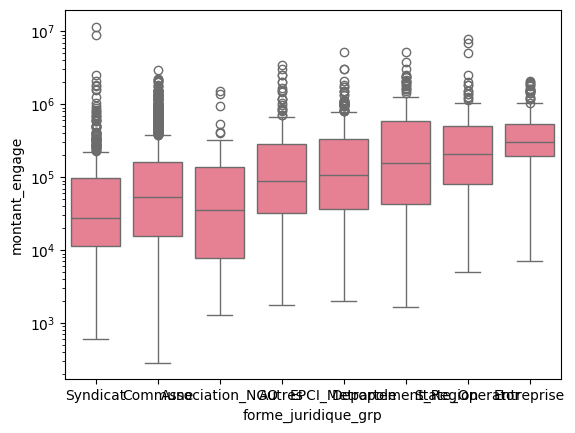

In [1779]:
sns.boxplot(
    x="forme_juridique_grp",
    y="montant_engage",
    data=df_agg,
    order=actor_order.keys()
)
plt.yscale("log")


In [1780]:
# median_map_entity = df_agg.groupby("forme_juridique_grp")["montant_engage"].median()
# df_agg["actor_prior"] = df_agg["forme_juridique_grp"].map(median_map_entity)
# df_agg["log_actor_prior"] = np.log1p(df_agg["actor_prior"])


In [1781]:
#ordinal encoding for categorieentreprise (PME < ETI < GE), 0 for missing
categorieentreprise_map = {
    'PME': 1,
    'ETI': 2,
    'GE': 3
}
df_agg['categorieentreprise'] = (
    df_agg['categorieentreprise']
    .astype('object')
    .map(categorieentreprise_map)
    .fillna(0)
)

In [1782]:
df_agg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 31 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        7094 non-null   object  
 1   resume_du_projet                     6917 non-null   object  
 2   montant_engage                       7094 non-null   float64 
 3   operateur                            7094 non-null   category
 4   demarche                             7094 non-null   object  
 5   forme_juridique_beneficiaire         6956 non-null   category
 6   activiteprincipale                   6929 non-null   category
 7   categorieentreprise                  7094 non-null   float64 
 8   economiesocialesolidaireunitelegale  7094 non-null   category
 9   is_false_info                        7094 non-null   int64   
 10  tranche_effectif_ord                 7094 non-null   int64   
 11  creation_year    

**!! do the same for test data**

In [1783]:
df_test_agg = df_test.copy()
df_test_agg["forme_juridique_grp"] = df_test_agg["forme_juridique_beneficiaire"].map(bucket_forme_juridique)
df_test_agg["naf_grp"] = df_test_agg["activiteprincipale"].map(bucket_naf)
#df_test_agg["ess_bin"] = (df_test_agg["economiesocialesolidaireunitelegale"] == "O").astype(int)
df_test_agg["demarche"] = df_test_agg["demarche"].map(bucket_demarche)
df_test_agg["operateur_type"] = df_test_agg["operateur"].map(bucket_operateur)
df_test_agg["has_operator"] = (df_test_agg["operateur_type"] != "None").astype(int)
df_test_agg["is_water_agency"] = (df_test_agg["operateur_type"] == "Water_agency").astype(int)
df_test_agg["is_ademe"] = (df_test_agg["operateur_type"] == "Environmental_agency").astype(int)
df_test_agg["is_financial_operator"] = (df_test_agg["operateur_type"] == "Financial_fund").astype(int)
df_test_agg["actor_rank"] = df_test_agg["forme_juridique_grp"].map(actor_order)


df_test_agg['categorieentreprise'] = (
    df_test_agg['categorieentreprise']
    .astype('object')
    .map(categorieentreprise_map)
    .fillna(0)
)

# df_test_agg["actor_prior"] = df_test_agg["forme_juridique_grp"].map(median_map_entity)
# df_test_agg["log_actor_prior"] = np.log1p(df_test_agg["actor_prior"])

# df_test_agg["naf_prior"] = df_test_agg["naf_grp"].map(median_map_naf)
# df_test_agg["log_naf_prior"] = np.log1p(df_test_agg["naf_prior"])

In [1784]:
df_test_agg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1774 entries, 0 to 1773
Data columns (total 30 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        1774 non-null   object  
 1   resume_du_projet                     1727 non-null   object  
 2   montant_engage                       1774 non-null   float64 
 3   operateur                            1774 non-null   category
 4   demarche                             1774 non-null   object  
 5   forme_juridique_beneficiaire         1734 non-null   category
 6   activiteprincipale                   1731 non-null   category
 7   categorieentreprise                  1774 non-null   float64 
 8   economiesocialesolidaireunitelegale  1774 non-null   category
 9   is_false_info                        1774 non-null   int64   
 10  tranche_effectif_ord                 1774 non-null   int64   
 11  creation_year    

In [1785]:
#drop original nominal columns after aggregation to avoid duplication
nominal_columns_to_drop = [
    "operateur",
    "forme_juridique_beneficiaire",
    "activiteprincipale",
    "economiesocialesolidaireunitelegale",
    "ess_bin",
    "france_region"

]

df_agg.drop(columns=[c for c in nominal_columns_to_drop if c in df_agg.columns], 
            inplace=True)
df_test_agg.drop(columns=[c for c in nominal_columns_to_drop if c in df_test_agg.columns], 
                 inplace=True)

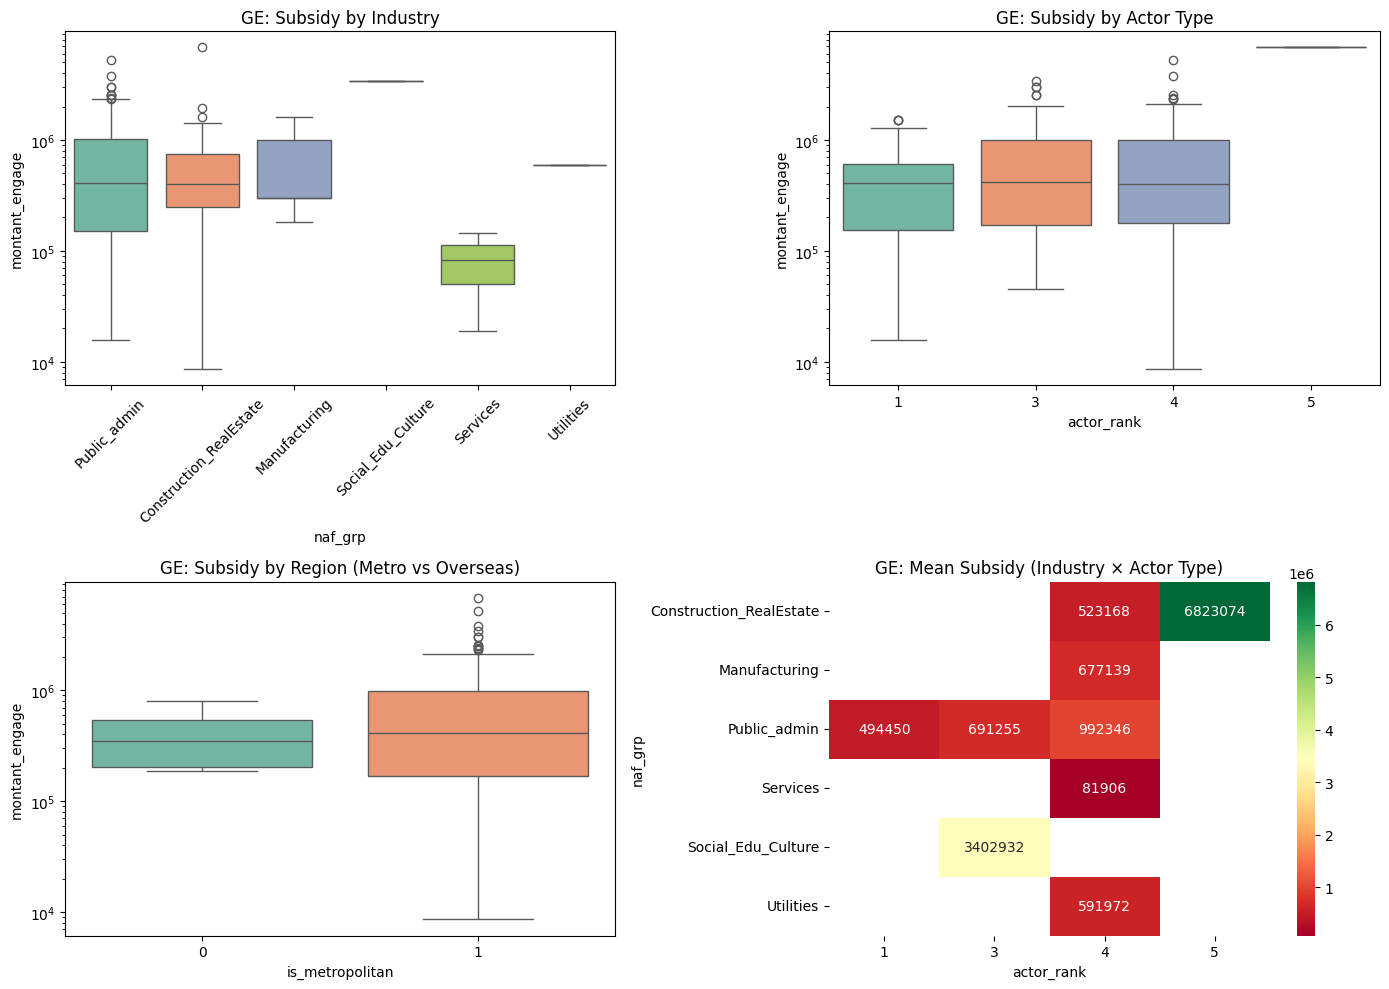

In [1786]:
# Visualize GE heterogeneity
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# GE by industry
ge_data = df_agg[df_agg['categorieentreprise'] == 3]
sns.boxplot(
    x='naf_grp', 
    y='montant_engage', 
    data=ge_data,
    ax=axes[0, 0],
    palette='Set2'
)
axes[0, 0].set_title('GE: Subsidy by Industry')
axes[0, 0].set_yscale('log')
axes[0, 0].tick_params(axis='x', rotation=45)

# GE by actor rank
sns.boxplot(
    x='actor_rank', 
    y='montant_engage', 
    data=ge_data,
    ax=axes[0, 1],
    palette='Set2'
)
axes[0, 1].set_title('GE: Subsidy by Actor Type')
axes[0, 1].set_yscale('log')

# GE by region
sns.boxplot(
    x='is_metropolitan', 
    y='montant_engage', 
    data=ge_data,
    ax=axes[1, 0],
    palette='Set2'
)
axes[1, 0].set_title('GE: Subsidy by Region (Metro vs Overseas)')
axes[1, 0].set_yscale('log')

# GE interaction heatmap
ge_interaction = ge_data.groupby(['naf_grp', 'actor_rank'])['montant_engage'].mean().unstack()
sns.heatmap(
    ge_interaction,
    annot=True,
    fmt='.0f',
    cmap='RdYlGn',
    ax=axes[1, 1]
)
axes[1, 1].set_title('GE: Mean Subsidy (Industry × Actor Type)')

plt.tight_layout()
plt.show()

In [1787]:
df_agg["categorieentreprise"].value_counts()

categorieentreprise
1.0    5252
2.0    1429
0.0     218
3.0     195
Name: count, dtype: int64

In [1788]:
# Create GE sub-stratification based on high-variance combinations
for df_data in [df_agg, df_test_agg]:
    # Flag top-subsidy GE archetypes
    df_data['is_ge'] = (df_data['categorieentreprise'] == 3).astype(int)
    
    # Archetype 1: GE × Public_admin × High Actor Rank (€992K median)
    # Public admin gets high subsidies across all actor ranks (1, 3, 5)
    df_data['ge_public_admin'] = (
        df_data['is_ge'] * 
        (df_data['naf_grp'] == 'Public_admin')
    ).astype(int)
    
    # Archetype 2: GE × Construction × Actor Rank 5 (€823K median)
    df_data['ge_construction_rank5'] = (
        df_data['is_ge'] * 
        (df_data['naf_grp'] == 'Construction_RealEstate') *
        (df_data['actor_rank'] == 5)
    ).astype(int)
    
    # Archetype 3: GE × Manufacturing (any actor) (€677K median)
    df_data['ge_manufacturing'] = (
        df_data['is_ge'] * 
        (df_data['naf_grp'] == 'Manufacturing')
    ).astype(int)
    
    # Archetype 4: GE × Utilities (any actor) (€592K median)
    df_data['ge_utilities'] = (
        df_data['is_ge'] * 
        (df_data['naf_grp'] == 'Utilities')
    ).astype(int)
    
    # Archetype 5: GE × Actor Rank 5 (State_Operator proxy) (highest rank)
    df_data['ge_rank5_actor'] = (
        df_data['is_ge'] * 
        (df_data['actor_rank'] == 5)
    ).astype(int)
    
    # Archetype 6: GE × Overseas (extreme variance, special handling)
    df_data['ge_overseas' ] = (
        df_data['is_ge'] * 
        df_data['is_overseas']
    ).astype(int)

print("GE archetypes created (for actual actor_rank 1-5):")
for col in ['ge_public_admin', 'ge_construction_rank5', 'ge_manufacturing', 'ge_utilities', 'ge_rank5_actor', 'ge_overseas']:
    count = df_agg[col].sum()
    if count > 0:
        median_val = df_agg[df_agg[col]==1]['montant_engage'].median()
        mean_val = df_agg[df_agg[col]==1]['montant_engage'].mean()
        print(f"  {col}: {count:4d} cases | median: €{median_val:9,.0f} | mean: €{mean_val:9,.0f}")
    else:
        print(f"  {col}: 0 cases")

GE archetypes created (for actual actor_rank 1-5):
  ge_public_admin:  133 cases | median: €  411,053 | mean: €  739,769
  ge_construction_rank5:    1 cases | median: €6,823,074 | mean: €6,823,074
  ge_manufacturing:    5 cases | median: €  300,000 | mean: €  677,139
  ge_utilities:    1 cases | median: €  591,972 | mean: €  591,972
  ge_rank5_actor:    1 cases | median: €6,823,074 | mean: €6,823,074
  ge_overseas:    5 cases | median: €  350,000 | mean: €  416,352


In [1789]:
for df_data in [df_agg, df_test_agg]:
    df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 32 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   nom_du_projet               7094 non-null   object 
 1   resume_du_projet            6917 non-null   object 
 2   montant_engage              7094 non-null   float64
 3   demarche                    7094 non-null   object 
 4   categorieentreprise         7094 non-null   float64
 5   is_false_info               7094 non-null   int64  
 6   tranche_effectif_ord        7094 non-null   int64  
 7   creation_year               6929 non-null   float64
 8   age_entreprise              7094 non-null   float64
 9   is_age_error                7094 non-null   int64  
 10  dept_population_proxy       7094 non-null   float64
 11  is_metropolitan             7094 non-null   int64  
 12  is_overseas                 7094 non-null   int64  
 13  dept_frequency_rank         7094 

### OHE on train and test

In [1790]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Define nominal columns for OneHotEncoding
nominal_to_encode = [
    "demarche",
    "forme_juridique_grp", 
    "naf_grp",
    "operateur_type",
    #"ess_bin",
    #"france_region"
]

df_encoded = df_agg.copy() #train

#OneHotEncoder on TRAIN
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore",
    drop="first"
)
encoder.fit(df_encoded[nominal_to_encode])

,categories,'auto'
,drop,'first'
,sparse_output,False
,dtype,<class 'numpy.float64'>
,handle_unknown,'ignore'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'


In [1791]:
# Transform train data with fitted encoder
nominal_ohe_train = encoder.transform(df_encoded[nominal_to_encode])
nominal_ohe_df_train = pd.DataFrame(
    nominal_ohe_train,
    columns=encoder.get_feature_names_out(nominal_to_encode),
    index=df_encoded.index
)

print(f"  Original columns: {len(nominal_to_encode)}")
print(f"  Encoded columns: {nominal_ohe_df_train.shape[1]}")
print(f"  Train samples: {nominal_ohe_df_train.shape[0]}")

  Original columns: 4
  Encoded columns: 22
  Train samples: 7094


In [1792]:
df_test_encoded = df_test_agg.copy()

In [1793]:
nominal_ohe_test = encoder.transform(df_test_encoded[nominal_to_encode])
nominal_ohe_df_test = pd.DataFrame(
    nominal_ohe_test,
    columns=encoder.get_feature_names_out(nominal_to_encode),
    index=df_test_encoded.index
)

print(f"  Original columns: {len(nominal_to_encode)}")
print(f"  Encoded columns: {nominal_ohe_test.shape[1]}")


  Original columns: 4
  Encoded columns: 22


In [1794]:
# Drop raw nominal variables after encoding
df_encoded.drop(columns=nominal_to_encode, inplace=True)
df_test_encoded.drop(columns=nominal_to_encode, inplace=True)

# Add one-hot encoded dataframes
df_encoded = pd.concat([df_encoded, nominal_ohe_df_train], axis=1)
df_test_encoded = pd.concat([df_test_encoded, nominal_ohe_df_test], axis=1)

print(f"  Train shape: {df_encoded.shape}")
print(f"  Test shape: {df_test_encoded.shape}")

  Train shape: (7094, 50)
  Test shape: (1774, 50)


### Target ordinal encoding for effectifs and firms' categoty

In [1795]:
# Target encoding for ordinal columns on TRAIN data
# Calculate mean target value for each category
tranche_effectif_target_mean = df_encoded.groupby('tranche_effectif_ord')['montant_engage'].mean()
categorieentreprise_target_mean = df_encoded.groupby('categorieentreprise')['montant_engage'].mean()

# Apply to train data
df_encoded['tranche_effectif_ord_te'] = df_encoded['tranche_effectif_ord'].map(tranche_effectif_target_mean)
df_encoded['categorieentreprise_te'] = df_encoded['categorieentreprise'].map(categorieentreprise_target_mean)

# Apply to test data (using train mappings)
df_test_encoded['tranche_effectif_ord_te'] = df_test_encoded['tranche_effectif_ord'].map(tranche_effectif_target_mean)
df_test_encoded['categorieentreprise_te'] = df_test_encoded['categorieentreprise'].map(categorieentreprise_target_mean)
print(f"tranche_effectif_ord: {len(tranche_effectif_target_mean)} categories")
print(f"categorieentreprise: {len(categorieentreprise_target_mean)} categories")

tranche_effectif_ord: 15 categories
categorieentreprise: 4 categories


In [1796]:
# # Drop original ordinal columns after target encoding
# df_encoded.drop(columns=['tranche_effectif_ord', 'categorieentreprise'], inplace=True)
# df_test_encoded.drop(columns=['tranche_effectif_ord', 'categorieentreprise'], inplace=True)

In [1797]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 52 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   nom_du_projet                           7094 non-null   object 
 1   resume_du_projet                        6917 non-null   object 
 2   montant_engage                          7094 non-null   float64
 3   categorieentreprise                     7094 non-null   float64
 4   is_false_info                           7094 non-null   int64  
 5   tranche_effectif_ord                    7094 non-null   int64  
 6   creation_year                           6929 non-null   float64
 7   age_entreprise                          7094 non-null   float64
 8   is_age_error                            7094 non-null   int64  
 9   dept_population_proxy                   7094 non-null   float64
 10  is_metropolitan                         7094 non-null   int6

### Text vectorization with TF-IDF

We decided to convert `Nom du projet`, `Resume du projet` to vector dimention to extract token based information from these long texts. Another way of doing this conversion is labeling (manual or automated).

Because subsidies are typically determined by:

- type of project (rénovation énergétique, éclairage public…)
- object category (école, mairie, batiment, salle, parc…)
- operations (réhabilitation, remplacement, création…)
- context (commune, ville, territoire)

TF–IDF captures these terms perfectly.

In [1798]:
df_encoded["resume_du_projet"] = df_encoded["resume_du_projet"].astype(str)
df_encoded["nom_du_projet"] = df_encoded["nom_du_projet"].astype(str)
df_test_encoded["resume_du_projet"] = df_test_encoded["resume_du_projet"].astype(str)
df_test_encoded["nom_du_projet"] = df_test_encoded["nom_du_projet"].astype(str)

In [1799]:
french_stopwords = [
    'le', 'de', 'un', 'et', 'a', 'etre', 'en', 'que', 'pour', 'dans',
    'ce', 'il', 'qui', 'ne', 'sur', 'se', 'pas', 'plus', 'pouvoir', 'par',
    'je', 'avec', 'tout', 'nous', 'ou', 'aller', 'vouloir', 'dire', 'elle',
    'aussi', 'bien', 'moi', 'autre', 'celui', 'meme', 'lui', 'avoir', 'nos',
    'vous', 'mon', 'son', 'ton', 'ta', 'ma', 'sa', 'ca', 'cet', 'cette',
    'ces', 'les', 'la', 'les', 'du', 'des', 'au', 'aux', 'sont', 'est',
    'etait', 'sera', 'seraient', 'peut', 'peuvent', 'faire', 'dois', 'doit',
    'dois', 'au', 'un', 'une', 'des', 'enfin', 'ete', 'ainsi', 'mise', 'dun',
    'afin', 'tres', 'moins', 'sous', 'etre', 'etre', 'ete', 'etre', 'depuis', 
    'entre', 'ainsi', 'cela', 'cela', 'ont', 'car', 'lorsque', 'lorsqu',
    'objectif', 'objectifs', 'mettre', 'oeuvre',
    'cadre', 'afin', 'vise', 'permettra', 'ca', 'etait', 'meme',
    'projet', 'programme', 'operation', 'dispositif', 'action',
    'realisation', 'mise', 'place', 'generalisation',
    'appui', 'territorial', 'cadre',
    #'etudes', 'prealables', 'etude',
    #'creation', 'construction', 'acquisition',
    #'investissements', 'restructuration', 'rehabilitation',
    #'renovation', 'renouvellement', 'modernisation',
    'amenagement', 
    #'recyclage', 
    'gestion',
    'commune', 'communal', 'communale', 'communaux',
    'collectivite', 'collectivites',
    'territoire', 'perimetre',
    'centre', 'zone', 'zac',
    'mairie', 'ecole', 'ecoles',
    'groupe', 'scolaire',
    'batiment', 'batiments',
    'parc', 'ensemble',
    'local', 'locaux',
    'maison', 'salle',
    'annee', '2020', '2021', '2022', '2023', '2024',
    'ancien', 'ancienne', 'nouveau', 'nouvelle',
    'plus', 'moins',
]


from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words=french_stopwords,
    ngram_range=(1,1),
    min_df=2,
    max_df=0.8,
    max_features=3,
    sublinear_tf=True,
    norm="l2",
    strip_accents="unicode",
)

# FIT on train
tfidf.fit(df_encoded['nom_du_projet'].astype(str).fillna(''))

# Transform train
resume_tfidf_train = tfidf.transform(df_encoded['nom_du_projet'].astype(str).fillna(''))

# Convert to dataframe
resume_vec_train = pd.DataFrame(
    resume_tfidf_train.toarray(), 
    columns=[f'tfidf_{i}' for i in range(resume_tfidf_train.shape[1])],
    index=df_encoded.index
)


In [1800]:
resume_vec_train.head()


,tfidf_0,tfidf_1,tfidf_2
0,0.000000,0.0,0.000000
1,0.000000,0.0,0.000000
2,0.000000,0.0,0.000000
3,0.000000,0.0,1.000000
4,0.778024,0.0,0.628234


In [1801]:
sparsity = resume_tfidf_train.nnz / (resume_tfidf_train.shape[0] * resume_tfidf_train.shape[1])
print(f"TF-IDF sparsity: {sparsity:.4f}")


TF-IDF sparsity: 0.1932


In [1802]:
vocab = tfidf.get_feature_names_out()
idfs = tfidf.idf_
sorted_words = sorted(zip(idfs, vocab))[:50]
print("Top 10 words by IDF:", sorted_words[:10])


Top 10 words by IDF: [(np.float64(2.2251011867208854), 'renovation'), (np.float64(2.755633473097986), 'energetique'), (np.float64(3.1775463204151766), 'public')]


**!! do the same for train**

In [1803]:
# Transform test data with fitted TF-IDF vectorizer
resume_tfidf_test = tfidf.transform(df_test_encoded['resume_du_projet'].astype(str).fillna(''))

# Convert to dataframe
resume_vec_test = pd.DataFrame(
    resume_tfidf_test.toarray(), 
    columns=[f'tfidf_{i}' for i in range(resume_tfidf_test.shape[1])],
    index=df_test_encoded.index
)

print(f"  Test samples: {resume_vec_test.shape[0]}")
print(f"  TF-IDF features: {resume_vec_test.shape[1]}")

  Test samples: 1774
  TF-IDF features: 3


In [1804]:
# drop textual variable and add vectorized forms resume_vec_test
df_encoded.drop(columns=text_columns, inplace=True)
df_test_encoded.drop(columns=text_columns, inplace=True)

# Add one-hot encoded dataframes
df_encoded = pd.concat([df_encoded, resume_vec_train], axis=1)
df_test_encoded = pd.concat([df_test_encoded, resume_vec_test], axis=1)

print(f"  Train shape: {df_encoded.shape}")
print(f"  Test shape: {df_test_encoded.shape}")

  Train shape: (7094, 53)
  Test shape: (1774, 53)


---

### 5. Target vs Feature Relationship Analysis

Visualize relationships between the target variable (subsidy amount) and key features to understand predictive patterns and guide feature selection.

In [1805]:
# Prepare data for visualization (use cleaned data)
X_viz = df_encoded.drop('montant_engage', axis=1)
y_viz = df_encoded['montant_engage']
print(f"Target range: €{y_viz.min():,.0f} - €{y_viz.max():,.0f}")

Target range: €288 - €11,600,000


Log-transformed features show moderate to weak correlations with target. However `tranche_effectif_ord_te` demonstrates the strongest relationship, suggesting company size is predictive. The trend lines reveal non-linear patterns that tree-based models can capture effectively.

In [1806]:
# Simple binary feature check
binary_features = [
    'is_age_error', 
    'is_false_info', 'is_metropolitan', 'is_overseas',
    'has_operator', 'is_water_agency', 'is_ademe', 'is_financial_operator'
]

binary_features = [f for f in binary_features if f in X_viz.columns]

rows = []
for feature in binary_features:
    no_mask = X_viz[feature] == 0
    yes_mask = X_viz[feature] == 1

    count_0 = no_mask.sum()
    count_1 = yes_mask.sum()
    mean_0 = y_viz[no_mask].mean()
    mean_1 = y_viz[yes_mask].mean()
    diff = mean_1 - mean_0
    pct_diff = (diff / mean_0 * 100) if mean_0 != 0 else 0

    rows.append({
        'feature': feature,
        'no_count': int(count_0),
        'no_mean': float(mean_0),
        'yes_count': int(count_1),
        'yes_mean': float(mean_1),
        'diff_pct': pct_diff
    })

binary_stats = pd.DataFrame(rows).sort_values(by='diff_pct', ascending=False)

display(binary_stats)

,feature,no_count,no_mean,yes_count,yes_mean,diff_pct
1,is_false_info,6950,177520.432351,144,388464.618542,118.828117
6,is_ademe,6781,173798.651138,313,355198.902684,104.373797
3,is_overseas,6955,178763.760063,139,333841.429281,86.750060
4,has_operator,6022,180765.341363,1072,187627.821101,3.796347
7,is_financial_operator,7007,182038.992174,87,162743.583333,-10.599602
0,is_age_error,2970,230624.238438,4124,146642.076079,-36.415150
2,is_metropolitan,336,279838.934315,6758,176928.089373,-36.775027
5,is_water_agency,6422,189022.864214,672,112799.220134,-40.325092


Key observations on binary features (auto-detected):
- Sorted by percent difference in mean subsidy between classes.
- Focus on features with both classes present; single-class columns are skipped.
- Use the top rows to identify impactful binary flags for modeling/feature selection.

### Analysis of OHE features

Each one-hot encoded category is evaluated for its effect size on subsidy amounts. Categories with high variance in mean subsidies are more predictive. The sorting by `diff_pct` identifies which project types and jurisdictions receive substantially different funding levels.

In [1807]:
X_cat = df_encoded.drop(columns=['montant_engage'])
y_cat = df_encoded['montant_engage']

binary_features_done = [
    'is_age_error',
    'is_false_info','is_metropolitan','is_overseas',
    'has_operator','is_water_agency','is_ademe','is_financial_operator'
]

prefixes = ['demarche_','forme_juridique_grp_','naf_grp_','operateur_type_','france_region_']
cat_ohe_cols = []
for name in X_cat.columns:
    for p in prefixes:
        if name.startswith(p):
            cat_ohe_cols.append(name)
            break

rows = []
for col in sorted(cat_ohe_cols):
    if col in binary_features_done:
        continue
    # keep only binary columns
    unique_vals = set(X_cat[col].unique())
    if not unique_vals.issubset({0, 1}):
        continue
    no_mask = X_cat[col] == 0
    yes_mask = X_cat[col] == 1
    n_no = int(no_mask.sum())
    n_yes = int(yes_mask.sum())
    mean_no = float(y_cat[no_mask].mean())
    mean_yes = float(y_cat[yes_mask].mean())
    diff = mean_yes - mean_no
    pct_diff = (diff / mean_no * 100) if mean_no != 0 else np.nan
    rows.append({
        'feature': col,
        'no_count': n_no,
        'no_mean': mean_no,
        'yes_count': n_yes,
        'yes_mean': mean_yes,
        'diff_pct': pct_diff
    })

cat_ohe_stats = pd.DataFrame(rows).sort_values(by='diff_pct', ascending=False)

# Filter to keep only features with |pct_diff| >= 100
cat_ohe_stats_filtered = cat_ohe_stats[cat_ohe_stats['diff_pct'].abs() >= 100]

print(f"Total OHE features: {len(cat_ohe_stats)}")
print(f"Features with |pct_diff| >= 100: {len(cat_ohe_stats_filtered)}")

display(cat_ohe_stats)

Total OHE features: 22
Features with |pct_diff| >= 100: 7


,feature,no_count,no_mean,yes_count,yes_mean,diff_pct
11,forme_juridique_grp_State_Operator,6956,175181.898784,138,515511.753406,194.272272
8,forme_juridique_grp_Departement_Region,6879,172895.638889,215,466775.860419,169.975497
13,naf_grp_Engineering_Technical,7038,179411.989852,56,482220.095179,168.778076
10,forme_juridique_grp_Entreprise,6724,168454.380559,370,424374.743324,151.922652
17,naf_grp_Social_Edu_Culture,7056,180388.052885,38,444416.019737,146.366659
14,naf_grp_Manufacturing,7005,179268.254328,89,381256.048764,112.673488
18,naf_grp_Utilities,6985,178730.008425,109,378686.248257,111.876143
16,naf_grp_Services,7041,180465.114890,53,359453.508868,99.181714
0,demarche_Biodiversite_sols,5613,163757.210479,1481,250193.576968,52.783243
9,forme_juridique_grp_EPCI_Metropole,6615,175618.068172,479,267207.492589,52.152620


In [1808]:
# # Apply filtering: keep only high-impact OHE features
# selected_ohe_features = cat_ohe_stats_filtered['feature'].tolist()

# # Identify all OHE columns in the datasets
# all_ohe_cols = [col for col in df_encoded.columns if any(col.startswith(p) for p in prefixes)]
# ohe_cols_to_drop = [col for col in all_ohe_cols if col not in selected_ohe_features]

# # Drop low-impact OHE features from both train and test
# df_encoded.drop(columns=ohe_cols_to_drop, inplace=True)
# df_test_encoded.drop(columns=ohe_cols_to_drop, inplace=True)

# print(f"Dropped {len(ohe_cols_to_drop)} low-impact OHE features")
# print(f"Kept {len(selected_ohe_features)} high-impact OHE features")
# print(f"Final train shape: {df_encoded.shape}")
# print(f"Final test shape: {df_test_encoded.shape}")

---

### Final dataset assembly 

In [1809]:
# Create top 1% subsidy dummy (99th percentile threshold)
# Compute threshold on TRAIN data only
threshold_99 = df_encoded['montant_engage'].quantile(0.99)
print(f"99th percentile threshold: €{threshold_99:,.0f}")

# Apply to both train and test
df_encoded['is_top_1pct'] = (df_encoded['montant_engage'] > threshold_99).astype(int)
df_test_encoded['is_top_1pct'] = (df_test_encoded['montant_engage'] > threshold_99).astype(int)

# Summary statistics
print(f"\nTrain - Top 1%: {df_encoded['is_top_1pct'].sum()} samples ({df_encoded['is_top_1pct'].mean()*100:.2f}%)")
print(f"Test  - Top 1%: {df_test_encoded['is_top_1pct'].sum()} samples ({df_test_encoded['is_top_1pct'].mean()*100:.2f}%)") 
# Mean subsidy comparison
mean_top1 = df_encoded[df_encoded['is_top_1pct']==1]['montant_engage'].mean()
mean_rest = df_encoded[df_encoded['is_top_1pct']==0]['montant_engage'].mean()
print(f"\nMean subsidy (top 1%): €{mean_top1:,.0f}")
print(f"Mean subsidy (rest 99%): €{mean_rest:,.0f}")
print(f"Difference: {(mean_top1/mean_rest - 1)*100:+.1f}%")

99th percentile threshold: €1,551,194

Train - Top 1%: 71 samples (1.00%)
Test  - Top 1%: 20 samples (1.13%)

Mean subsidy (top 1%): €2,599,728
Mean subsidy (rest 99%): €157,358
Difference: +1552.1%


In [1810]:
df_encoded.to_csv(project_root / "data" / "df_final.csv", index=False)
df_test_encoded.to_csv(project_root / "data" / "df_test.csv", index=False)
print ("ready!")

ready!


In [1811]:
# Create base final datasets (copies of encoded data for modeling)
df_final_train = df_encoded.copy()
df_final_test = df_test_encoded.copy()

print(f"  df_final_train: {df_final_train.shape}")
print(f"  df_final_test: {df_final_test.shape}")

  df_final_train: (7094, 54)
  df_final_test: (1774, 54)


In [1726]:
df_final_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 53 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   montant_engage                          7094 non-null   float64
 1   categorieentreprise                     7094 non-null   float64
 2   is_false_info                           7094 non-null   int64  
 3   tranche_effectif_ord                    7094 non-null   int64  
 4   creation_year                           6929 non-null   float64
 5   age_entreprise                          7094 non-null   float64
 6   is_age_error                            7094 non-null   int64  
 7   dept_population_proxy                   7094 non-null   float64
 8   is_metropolitan                         7094 non-null   int64  
 9   is_overseas                             7094 non-null   int64  
 10  dept_frequency_rank                     7094 non-null   floa